In [35]:
 import numpy as np
import pandas as pd

from scipy.spatial.distance import cdist
from sklearn.linear_model import LinearRegression

np.random.seed(123)

# =====================================================
# PARAMETERS
# =====================================================

n = 200

beta_direct = 1.0
beta_spill = 2.0

# =====================================================
# SPATIAL LOCATIONS
# =====================================================

coords = np.random.uniform(
    0,
    10,
    (n, 2)
)

D = cdist(coords, coords)

# =====================================================
# TRUE TRANSPORT OPERATOR
# =====================================================

T_true = np.exp(-D / 2)

np.fill_diagonal(T_true, 1)

T_true = (
    T_true /
    T_true.sum(
        axis=1,
        keepdims=True
    )
)

# =====================================================
# POLICY
# A = emission reduction treatment
# =====================================================

A = np.random.binomial(
    1,
    0.30,
    n
)

# =====================================================
# TRUE EXPOSURE
# =====================================================

E_true = T_true @ A

# =====================================================
# OBSERVED PM
# =====================================================

PM = (
    E_true
    +
    np.random.normal(
        0,
        0.01,
        n
    )
)

# =====================================================
# HEALTH OUTCOME
# =====================================================

H = (
    beta_direct * A
    +
    beta_spill * E_true
    +
    np.random.normal(
        0,
        0.05,
        n
    )
)

# =====================================================
# OBSERVATIONALLY EQUIVALENT OPERATORS
# =====================================================

T1 = T_true.copy()

# -----------------------------------------------------
# Alternative 1
# -----------------------------------------------------

noise1 = np.random.normal(
    0,
    0.01,
    T_true.shape
)

T2 = T_true + noise1

T2[T2 < 0] = 0

T2 = (
    T2 /
    T2.sum(
        axis=1,
        keepdims=True
    )
)

# -----------------------------------------------------
# Alternative 2
# -----------------------------------------------------

noise2 = np.random.normal(
    0,
    0.02,
    T_true.shape
)

T3 = T_true + noise2

T3[T3 < 0] = 0

T3 = (
    T3 /
    T3.sum(
        axis=1,
        keepdims=True
    )
)

# -----------------------------------------------------
# Alternative 3
# -----------------------------------------------------

noise3 = np.random.normal(
    0,
    0.03,
    T_true.shape
)

T4 = T_true + noise3

T4[T4 < 0] = 0

T4 = (
    T4 /
    T4.sum(
        axis=1,
        keepdims=True
    )
)

# =====================================================
# EVALUATION
# =====================================================

results = []

for name, T in [

    ("True", T1),

    ("Alt1", T2),

    ("Alt2", T3),

    ("Alt3", T4)

]:

    E = T @ A

    pm_rmse = np.sqrt(
        np.mean(
            (PM - E) ** 2
        )
    )

    pm_r2 = (
        np.corrcoef(
            PM,
            E
        )[0, 1]
    ) ** 2

    exposure_rmse = np.sqrt(
        np.mean(
            (E - E_true) ** 2
        )
    )

    X = np.column_stack(
        [A, E]
    )

    fit = LinearRegression()

    fit.fit(
        X,
        H
    )

    beta_hat = fit.coef_[1]

    spillover_error = abs(
        beta_hat - beta_spill
    )

    operator_corr = np.corrcoef(
        T_true.flatten(),
        T.flatten()
    )[0, 1]

    results.append([

        name,

        pm_rmse,

        pm_r2,

        exposure_rmse,

        beta_hat,

        spillover_error,

        operator_corr

    ])

results = pd.DataFrame(

    results,

    columns=[

        "Model",

        "PM_RMSE",

        "PM_R2",

        "Exposure_RMSE",

        "Spillover_Beta",

        "Spillover_Error",

        "Operator_Corr"

    ]

)

print("\nRESULTS\n")
print(results)

print("\nTRUE SPILLOVER =", beta_spill)

# =====================================================
# CORY TABLE
# =====================================================

cory_table = results[[
    "Model",
    "PM_R2",
    "Exposure_RMSE",
    "Spillover_Beta"
]]

print("\nCORY TABLE\n")
print(cory_table)


RESULTS

  Model   PM_RMSE     PM_R2  Exposure_RMSE  Spillover_Beta  Spillover_Error  \
0  True  0.009781  0.955290       0.000000        2.253153         0.253153   
1  Alt1  0.038077  0.408259       0.037362        1.463009         0.536991   
2  Alt2  0.052753  0.128072       0.051645        0.735804         1.264196   
3  Alt3  0.056068  0.053199       0.055066        0.514281         1.485719   

   Operator_Corr  
0       1.000000  
1       0.551840  
2       0.301764  
3       0.201694  

TRUE SPILLOVER = 2.0

CORY TABLE

  Model     PM_R2  Exposure_RMSE  Spillover_Beta
0  True  0.955290       0.000000        2.253153
1  Alt1  0.408259       0.037362        1.463009
2  Alt2  0.128072       0.051645        0.735804
3  Alt3  0.053199       0.055066        0.514281


In [36]:
import numpy as np
import pandas as pd

from scipy.spatial.distance import cdist
from sklearn.linear_model import LinearRegression

np.random.seed(123)

# =====================================================
# PARAMETERS
# =====================================================

n = 200

beta_direct = 1.0
beta_spill = 2.0

# =====================================================
# SPATIAL LOCATIONS
# =====================================================

coords = np.random.uniform(
    0,
    10,
    (n, 2)
)

D = cdist(coords, coords)

# =====================================================
# TRUE TRANSPORT OPERATOR
# =====================================================

T_true = np.exp(-D / 2)

np.fill_diagonal(
    T_true,
    1
)

T_true = (
    T_true /
    T_true.sum(
        axis=1,
        keepdims=True
    )
)

# =====================================================
# POLICY
# =====================================================

A = np.random.binomial(
    1,
    0.30,
    n
)

# =====================================================
# TRUE EXPOSURE
# =====================================================

E_true = T_true @ A

# =====================================================
# OBSERVED PM
# =====================================================

PM = (
    E_true
    +
    np.random.normal(
        0,
        0.005,
        n
    )
)

# =====================================================
# HEALTH OUTCOME
# =====================================================

H = (
    beta_direct * A
    +
    beta_spill * E_true
    +
    np.random.normal(
        0,
        0.02,
        n
    )
)

# =====================================================
# OBSERVATIONALLY EQUIVALENT OPERATORS
# =====================================================

T1 = T_true.copy()

# -----------------------------------------------------
# Alt1
# -----------------------------------------------------

noise = np.random.normal(
    0,
    0.001,
    T_true.shape
)

T2 = 0.99 * T_true + noise

T2[T2 < 0] = 0

T2 = (
    T2 /
    T2.sum(
        axis=1,
        keepdims=True
    )
)

# -----------------------------------------------------
# Alt2
# -----------------------------------------------------

noise = np.random.normal(
    0,
    0.002,
    T_true.shape
)

T3 = 0.98 * T_true + noise

T3[T3 < 0] = 0

T3 = (
    T3 /
    T3.sum(
        axis=1,
        keepdims=True
    )
)

# -----------------------------------------------------
# Alt3
# -----------------------------------------------------

noise = np.random.normal(
    0,
    0.005,
    T_true.shape
)

T4 = 0.95 * T_true + noise

T4[T4 < 0] = 0

T4 = (
    T4 /
    T4.sum(
        axis=1,
        keepdims=True
    )
)

# =====================================================
# EVALUATION
# =====================================================

results = []

for name, T in [

    ("True", T1),
    ("Alt1", T2),
    ("Alt2", T3),
    ("Alt3", T4)

]:

    E = T @ A

    pm_rmse = np.sqrt(
        np.mean(
            (PM - E) ** 2
        )
    )

    pm_r2 = (
        np.corrcoef(
            PM,
            E
        )[0, 1]
    ) ** 2

    exposure_rmse = np.sqrt(
        np.mean(
            (E - E_true) ** 2
        )
    )

    X = np.column_stack(
        [A, E]
    )

    fit = LinearRegression()

    fit.fit(
        X,
        H
    )

    beta_hat = fit.coef_[1]

    spillover_error = abs(
        beta_hat - beta_spill
    )

    operator_corr = np.corrcoef(
        T_true.flatten(),
        T.flatten()
    )[0, 1]

    results.append([

        name,
        pm_rmse,
        pm_r2,
        exposure_rmse,
        beta_hat,
        spillover_error,
        operator_corr

    ])

results = pd.DataFrame(

    results,

    columns=[

        "Model",
        "PM_RMSE",
        "PM_R2",
        "Exposure_RMSE",
        "Spillover_Beta",
        "Spillover_Error",
        "Operator_Corr"

    ]

)

print("\n================ RESULTS ================\n")
print(results)

print("\nTRUE SPILLOVER =", beta_spill)

print("\n================ CORY TABLE ================\n")

print(
    results[
        [
            "Model",
            "PM_R2",
            "Exposure_RMSE",
            "Spillover_Beta",
            "Operator_Corr"
        ]
    ]
)


================ RESULTS ================

  Model   PM_RMSE     PM_R2  Exposure_RMSE  Spillover_Beta  Spillover_Error  \
0  True  0.004891  0.988319       0.000000        2.101261         0.101261   
1  Alt1  0.007693  0.971095       0.006200        2.055836         0.055836   
2  Alt2  0.013669  0.909846       0.012852        2.041461         0.041461   
3  Alt3  0.025960  0.675041       0.025501        1.863569         0.136431   

   Operator_Corr  
0       1.000000  
1       0.987266  
2       0.954285  
3       0.792327  

TRUE SPILLOVER = 2.0

================ CORY TABLE ================

  Model     PM_R2  Exposure_RMSE  Spillover_Beta  Operator_Corr
0  True  0.988319       0.000000        2.101261       1.000000
1  Alt1  0.971095       0.006200        2.055836       0.987266
2  Alt2  0.909846       0.012852        2.041461       0.954285
3  Alt3  0.675041       0.025501        1.863569       0.792327


In [37]:
import numpy as np
import pandas as pd

from scipy.spatial.distance import cdist
from sklearn.linear_model import LinearRegression

np.random.seed(123)

# =====================================================
# PARAMETERS
# =====================================================

n = 300

beta_direct = 1.0
beta_spill = 2.0

# =====================================================
# SPATIAL LOCATIONS
# =====================================================

coords = np.random.uniform(
    0,
    10,
    (n, 2)
)

D = cdist(coords, coords)

# =====================================================
# TRUE TRANSPORT OPERATOR
# =====================================================

T_true = np.exp(-D / 2)

np.fill_diagonal(
    T_true,
    1
)

T_true = (
    T_true /
    T_true.sum(
        axis=1,
        keepdims=True
    )
)

# =====================================================
# LOCALIZED POLICY
# =====================================================

A = np.zeros(n)

center = np.array([5, 5])

dist_center = np.sqrt(
    np.sum(
        (coords - center) ** 2,
        axis=1
    )
)

A[dist_center < 2] = 1

# =====================================================
# TRUE EXPOSURE
# =====================================================

E_true = T_true @ A

# =====================================================
# OBSERVED PM
# =====================================================

PM = (
    E_true
    +
    np.random.normal(
        0,
        0.005,
        n
    )
)

# =====================================================
# HEALTH OUTCOME
# NONLINEAR SPILLOVER
# =====================================================

H = (
    beta_direct * A
    +
    beta_spill * (E_true ** 2)
    +
    np.random.normal(
        0,
        0.02,
        n
    )
)

# =====================================================
# OBSERVATIONALLY EQUIVALENT OPERATORS
# =====================================================

T1 = T_true.copy()

noise = np.random.normal(
    0,
    0.001,
    T_true.shape
)

T2 = 0.99 * T_true + noise

T2[T2 < 0] = 0

T2 = (
    T2 /
    T2.sum(
        axis=1,
        keepdims=True
    )
)

noise = np.random.normal(
    0,
    0.002,
    T_true.shape
)

T3 = 0.98 * T_true + noise

T3[T3 < 0] = 0

T3 = (
    T3 /
    T3.sum(
        axis=1,
        keepdims=True
    )
)

noise = np.random.normal(
    0,
    0.005,
    T_true.shape
)

T4 = 0.95 * T_true + noise

T4[T4 < 0] = 0

T4 = (
    T4 /
    T4.sum(
        axis=1,
        keepdims=True
    )
)

# =====================================================
# EVALUATION
# =====================================================

results = []

for name, T in [

    ("True", T1),
    ("Alt1", T2),
    ("Alt2", T3),
    ("Alt3", T4)

]:

    E = T @ A

    pm_rmse = np.sqrt(
        np.mean(
            (PM - E) ** 2
        )
    )

    pm_r2 = (
        np.corrcoef(
            PM,
            E
        )[0, 1]
    ) ** 2

    exposure_rmse = np.sqrt(
        np.mean(
            (E - E_true) ** 2
        )
    )

    X = np.column_stack(
        [
            A,
            E,
            E ** 2
        ]
    )

    fit = LinearRegression()

    fit.fit(
        X,
        H
    )

    beta_hat = fit.coef_[2]

    spillover_error = abs(
        beta_hat - beta_spill
    )

    operator_corr = np.corrcoef(
        T_true.flatten(),
        T.flatten()
    )[0, 1]

    results.append([

        name,
        pm_rmse,
        pm_r2,
        exposure_rmse,
        beta_hat,
        spillover_error,
        operator_corr

    ])

results = pd.DataFrame(

    results,

    columns=[

        "Model",
        "PM_RMSE",
        "PM_R2",
        "Exposure_RMSE",
        "Spillover_Beta",
        "Spillover_Error",
        "Operator_Corr"

    ]

)

print("\n================ RESULTS ================\n")
print(results)

print("\nTRUE SPILLOVER =", beta_spill)

print("\n================ CORY TABLE ================\n")

print(
    results[
        [
            "Model",
            "PM_R2",
            "Exposure_RMSE",
            "Spillover_Beta",
            "Operator_Corr"
        ]
    ]
)


================ RESULTS ================

  Model   PM_RMSE     PM_R2  Exposure_RMSE  Spillover_Beta  Spillover_Error  \
0  True  0.005112  0.993557       0.000000        1.565313         0.434687   
1  Alt1  0.007911  0.986299       0.005936        1.460601         0.539399   
2  Alt2  0.013231  0.968552       0.011881        1.409907         0.590093   
3  Alt3  0.029838  0.859795       0.028886        0.414497         1.585503   

   Operator_Corr  
0       1.000000  
1       0.973661  
2       0.911189  
3       0.655765  

TRUE SPILLOVER = 2.0

================ CORY TABLE ================

  Model     PM_R2  Exposure_RMSE  Spillover_Beta  Operator_Corr
0  True  0.993557       0.000000        1.565313       1.000000
1  Alt1  0.986299       0.005936        1.460601       0.973661
2  Alt2  0.968552       0.011881        1.409907       0.911189
3  Alt3  0.859795       0.028886        0.414497       0.655765


In [38]:
import numpy as np
import pandas as pd

from scipy.spatial.distance import cdist
from sklearn.linear_model import LinearRegression

np.random.seed(123)

# =====================================================
# PARAMETERS
# =====================================================

n = 500

beta_direct = 1.0
beta_spill = 2.0

# =====================================================
# LOCATIONS
# =====================================================

coords = np.random.uniform(
    0,
    10,
    (n, 2)
)

D = cdist(coords, coords)

# =====================================================
# TRUE TRANSPORT
# =====================================================

T_true = np.exp(-D / 1.5)

np.fill_diagonal(
    T_true,
    1
)

T_true = (
    T_true /
    T_true.sum(
        axis=1,
        keepdims=True
    )
)

# =====================================================
# POLICY
# LOCALIZED INTERVENTION
# =====================================================

A = np.zeros(n)

center = np.array([5, 5])

dist_center = np.sqrt(
    np.sum(
        (coords - center) ** 2,
        axis=1
    )
)

A[dist_center < 1.5] = 1

# =====================================================
# TRUE EXPOSURE
# =====================================================

E_true = T_true @ A

# =====================================================
# PM
# =====================================================

PM = (
    E_true
    +
    np.random.normal(
        0,
        0.01,
        n
    )
)

# =====================================================
# HEALTH OUTCOME
# TRUE MODEL
# =====================================================

H = (
    1.0 * A
    +
    2.0 * E_true
    +
    4.0 * (E_true > np.quantile(E_true,0.80))
    +
    np.random.normal(
        0,
        0.10,
        n
    )
)

# =====================================================
# CANDIDATE OPERATORS
# =====================================================

T1 = T_true.copy()

# -----------------------------------------------------
# PDE-LIKE
# -----------------------------------------------------

T2 = np.exp(-D / 1.7)

np.fill_diagonal(T2,1)

T2 = (
    T2 /
    T2.sum(
        axis=1,
        keepdims=True
    )
)

# -----------------------------------------------------
# PINO-LIKE
# -----------------------------------------------------

T3 = np.exp(-D / 1.3)

np.fill_diagonal(T3,1)

T3 = (
    T3 /
    T3.sum(
        axis=1,
        keepdims=True
    )
)

# -----------------------------------------------------
# FNO-LIKE
# -----------------------------------------------------

T4 = (
    0.5*T2
    +
    0.5*T3
)

T4 = (
    T4 /
    T4.sum(
        axis=1,
        keepdims=True
    )
)

# =====================================================
# EVALUATION
# =====================================================

rows = []

for name,T in [

    ("True PDE",T1),
    ("Misspecified PDE",T2),
    ("PINO",T3),
    ("FNO",T4)

]:

    E = T @ A

    pm_r2 = (
        np.corrcoef(
            PM,
            E
        )[0,1]
    )**2

    pm_rmse = np.sqrt(
        np.mean(
            (PM-E)**2
        )
    )

    exposure_rmse = np.sqrt(
        np.mean(
            (E-E_true)**2
        )
    )

    X = np.column_stack(
        [
            A,
            E
        ]
    )

    fit = LinearRegression()

    fit.fit(
        X,
        H
    )

    beta_hat = fit.coef_[1]

    operator_corr = np.corrcoef(
        T_true.flatten(),
        T.flatten()
    )[0,1]

    rows.append([

        name,
        pm_r2,
        pm_rmse,
        exposure_rmse,
        beta_hat,
        operator_corr

    ])

results = pd.DataFrame(

    rows,

    columns=[

        "Model",
        "PM_R2",
        "PM_RMSE",
        "Exposure_RMSE",
        "Spillover_Beta",
        "Operator_Corr"

    ]

)

print("\n================ MAIN TABLE ================\n")
print(results)

print("\nTRUE BETA =", beta_spill)

print("\n================ CORY TABLE ================\n")

print(
    results[
        [
            "Model",
            "PM_R2",
            "Spillover_Beta",
            "Operator_Corr"
        ]
    ]
)


================ MAIN TABLE ================

              Model     PM_R2   PM_RMSE  Exposure_RMSE  Spillover_Beta  \
0          True PDE  0.975201  0.009470       0.000000       28.471840   
1  Misspecified PDE  0.974672  0.012791       0.008722       31.713377   
2              PINO  0.971529  0.014786       0.011183       25.611645   
3               FNO  0.974754  0.009607       0.001321       28.397194   

   Operator_Corr  
0       1.000000  
1       0.997591  
2       0.996499  
3       0.999835  

TRUE BETA = 2.0

================ CORY TABLE ================

              Model     PM_R2  Spillover_Beta  Operator_Corr
0          True PDE  0.975201       28.471840       1.000000
1  Misspecified PDE  0.974672       31.713377       0.997591
2              PINO  0.971529       25.611645       0.996499
3               FNO  0.974754       28.397194       0.999835


In [39]:
import numpy as np
import pandas as pd

from scipy.spatial.distance import cdist
from sklearn.linear_model import LinearRegression

np.random.seed(123)

# =====================================================
# PARAMETERS
# =====================================================

n = 1000

beta_direct = 1.0
beta_spill = 2.0

# =====================================================
# SPATIAL LOCATIONS
# =====================================================

coords = np.random.uniform(
    0,
    10,
    (n,2)
)

D = cdist(coords,coords)

# =====================================================
# TRUE TRANSPORT
# =====================================================

T_true = np.exp(-D/1.5)

np.fill_diagonal(
    T_true,
    1
)

T_true = (
    T_true /
    T_true.sum(
        axis=1,
        keepdims=True
    )
)

# =====================================================
# POLICY
# =====================================================

A = np.zeros(n)

center = np.array([5,5])

dist_center = np.sqrt(
    np.sum(
        (coords-center)**2,
        axis=1
    )
)

A[dist_center < 1.5] = 1

# =====================================================
# TRUE EXPOSURE
# =====================================================

E_true = T_true @ A

# =====================================================
# PM OBSERVATION
# =====================================================

PM = (
    E_true
    +
    np.random.normal(
        0,
        0.01,
        n
    )
)

# =====================================================
# HEALTH OUTCOME
# TRUE SPILLOVER = 2
# =====================================================

H = (
    beta_direct*A
    +
    beta_spill*E_true
    +
    np.random.normal(
        0,
        0.05,
        n
    )
)

# =====================================================
# TRANSPORT MODELS
# =====================================================

# True PDE

T1 = T_true.copy()

# Misspecified PDE

T2 = np.exp(-D/1.7)

np.fill_diagonal(
    T2,
    1
)

T2 = (
    T2 /
    T2.sum(
        axis=1,
        keepdims=True
    )
)

# PINO-like

T3 = np.exp(-D/1.3)

np.fill_diagonal(
    T3,
    1
)

T3 = (
    T3 /
    T3.sum(
        axis=1,
        keepdims=True
    )
)

# FNO-like

T4 = (
    0.5*T2
    +
    0.5*T3
)

T4 = (
    T4 /
    T4.sum(
        axis=1,
        keepdims=True
    )
)

# =====================================================
# EVALUATION
# =====================================================

rows = []

for name,T in [

    ("True PDE",T1),
    ("Misspecified PDE",T2),
    ("PINO",T3),
    ("FNO",T4)

]:

    E = T @ A

    pm_r2 = (
        np.corrcoef(
            PM,
            E
        )[0,1]
    )**2

    pm_rmse = np.sqrt(
        np.mean(
            (PM-E)**2
        )
    )

    exposure_rmse = np.sqrt(
        np.mean(
            (E-E_true)**2
        )
    )

    X = np.column_stack(
        [
            A,
            E
        ]
    )

    fit = LinearRegression()

    fit.fit(
        X,
        H
    )

    beta_hat = fit.coef_[1]

    operator_corr = np.corrcoef(
        T_true.flatten(),
        T.flatten()
    )[0,1]

    rows.append([

        name,
        pm_r2,
        pm_rmse,
        exposure_rmse,
        beta_hat,
        operator_corr

    ])

results = pd.DataFrame(

    rows,

    columns=[

        "Model",
        "PM_R2",
        "PM_RMSE",
        "Exposure_RMSE",
        "Spillover_Beta",
        "Operator_Corr"

    ]

)

print("\n================ MAIN TABLE ================\n")
print(results)

print("\nTRUE SPILLOVER =", beta_spill)

print("\n================ CORY TABLE ================\n")

print(
    results[
        [
            "Model",
            "PM_R2",
            "Exposure_RMSE",
            "Spillover_Beta",
            "Operator_Corr"
        ]
    ]
)


================ MAIN TABLE ================

              Model     PM_R2   PM_RMSE  Exposure_RMSE  Spillover_Beta  \
0          True PDE  0.965062  0.009850       0.000000        1.995712   
1  Misspecified PDE  0.963325  0.012579       0.007632        2.249592   
2              PINO  0.962663  0.013734       0.009776        1.767335   
3               FNO  0.964955  0.009892       0.001154        1.983526   

   Operator_Corr  
0       1.000000  
1       0.997727  
2       0.996695  
3       0.999852  

TRUE SPILLOVER = 2.0

================ CORY TABLE ================

              Model     PM_R2  Exposure_RMSE  Spillover_Beta  Operator_Corr
0          True PDE  0.965062       0.000000        1.995712       1.000000
1  Misspecified PDE  0.963325       0.007632        2.249592       0.997727
2              PINO  0.962663       0.009776        1.767335       0.996695
3               FNO  0.964955       0.001154        1.983526       0.999852


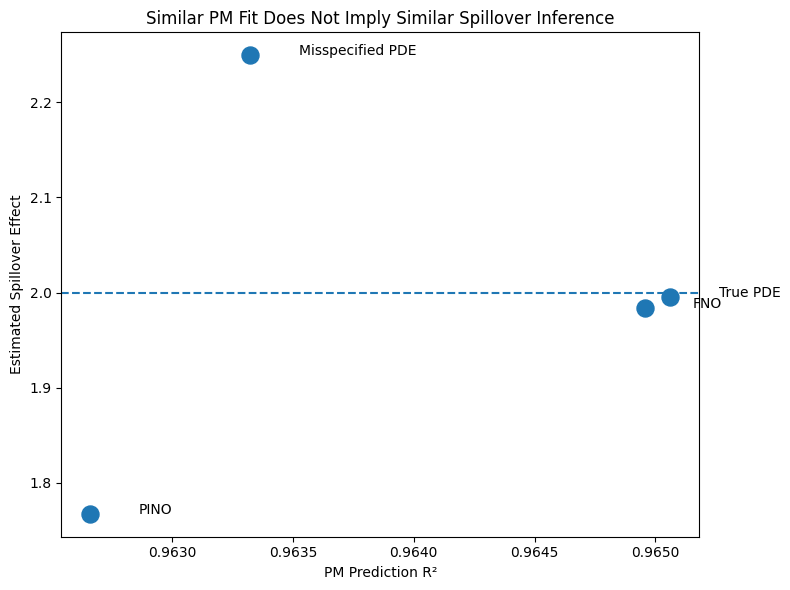

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(
    results["PM_R2"],
    results["Spillover_Beta"],
    s=150
)

for i,row in results.iterrows():

    plt.text(
        row["PM_R2"]+0.0002,
        row["Spillover_Beta"],
        row["Model"]
    )

plt.axhline(
    2.0,
    linestyle="--"
)

plt.xlabel("PM Prediction R²")
plt.ylabel("Estimated Spillover Effect")

plt.title(
    "Similar PM Fit Does Not Imply Similar Spillover Inference"
)

plt.tight_layout()

plt.show()

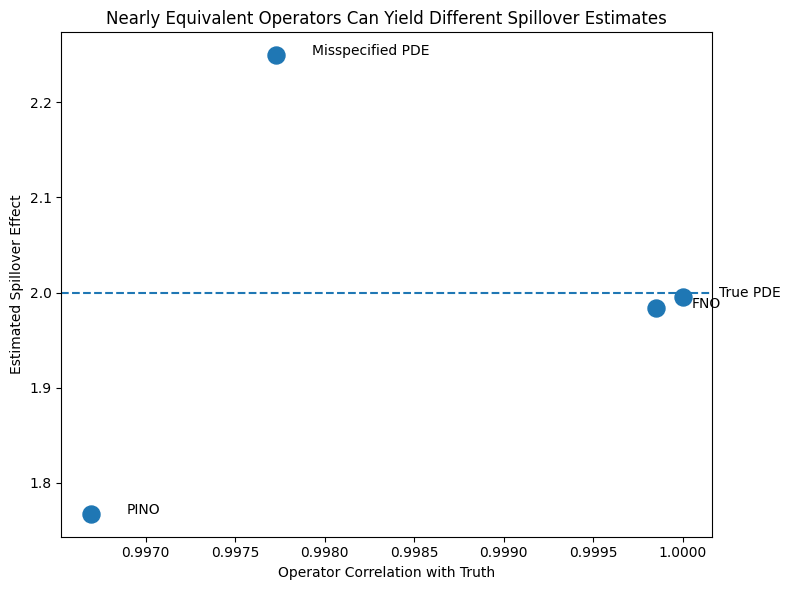

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(
    results["Operator_Corr"],
    results["Spillover_Beta"],
    s=150
)

for i,row in results.iterrows():

    plt.text(
        row["Operator_Corr"]+0.0002,
        row["Spillover_Beta"],
        row["Model"]
    )

plt.axhline(
    2.0,
    linestyle="--"
)

plt.xlabel("Operator Correlation with Truth")
plt.ylabel("Estimated Spillover Effect")

plt.title(
    "Nearly Equivalent Operators Can Yield Different Spillover Estimates"
)

plt.tight_layout()

plt.show()

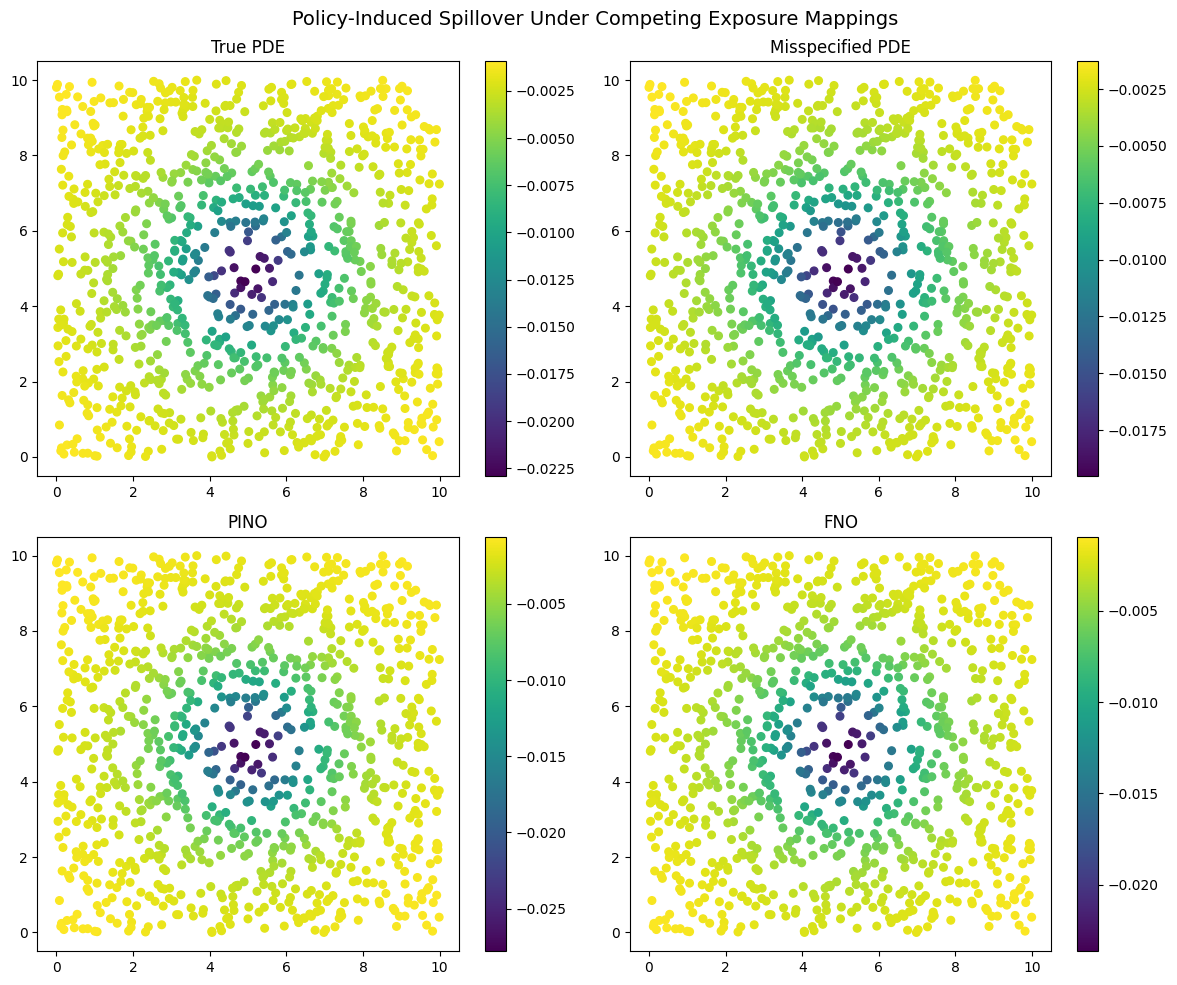

In [42]:
# =====================================================
# FIGURE 2
# POLICY SPILLOVER MAP
# =====================================================

import numpy as np
import matplotlib.pyplot as plt

# -----------------------------------------------------
# NEW POLICY:
# Sacramento-like intervention
# -----------------------------------------------------

A_policy = np.zeros(n)

policy_center = np.array([5, 5])

policy_dist = np.sqrt(
    np.sum(
        (coords - policy_center) ** 2,
        axis=1
    )
)

A_policy[policy_dist < 1.0] = -0.20

# -----------------------------------------------------
# SPILLOVER UNDER EACH MODEL
# -----------------------------------------------------

spill_true = T1 @ A_policy

spill_pde = T2 @ A_policy

spill_pino = T3 @ A_policy

spill_fno = T4 @ A_policy

# -----------------------------------------------------
# FIGURE
# -----------------------------------------------------

fig, ax = plt.subplots(
    2,
    2,
    figsize=(12,10)
)

plots = [

    ("True PDE", spill_true),

    ("Misspecified PDE", spill_pde),

    ("PINO", spill_pino),

    ("FNO", spill_fno)

]

for k,(title,spill) in enumerate(plots):

    r = k // 2
    c = k % 2

    sc = ax[r,c].scatter(

        coords[:,0],
        coords[:,1],

        c=spill,

        s=30
    )

    ax[r,c].set_title(title)

    plt.colorbar(
        sc,
        ax=ax[r,c]
    )

plt.suptitle(
    "Policy-Induced Spillover Under Competing Exposure Mappings",
    fontsize=14
)

plt.tight_layout()

plt.show()

In [43]:
# =====================================================
# POLICY COMPARISON TABLE
# =====================================================

policy_table = pd.DataFrame({

    "Model":[

        "True PDE",

        "Misspecified PDE",

        "PINO",

        "FNO"

    ],

    "Mean Spillover":[

        spill_true.mean(),

        spill_pde.mean(),

        spill_pino.mean(),

        spill_fno.mean()

    ],

    "Max Spillover":[

        spill_true.max(),

        spill_pde.max(),

        spill_pino.max(),

        spill_fno.max()

    ],

    "Min Spillover":[

        spill_true.min(),

        spill_pde.min(),

        spill_pino.min(),

        spill_fno.min()

    ]

})

print(policy_table)

              Model  Mean Spillover  Max Spillover  Min Spillover
0          True PDE       -0.004473      -0.000933      -0.022903
1  Misspecified PDE       -0.004602      -0.001281      -0.019504
2              PINO       -0.004312      -0.000595      -0.027798
3               FNO       -0.004457      -0.000938      -0.023651


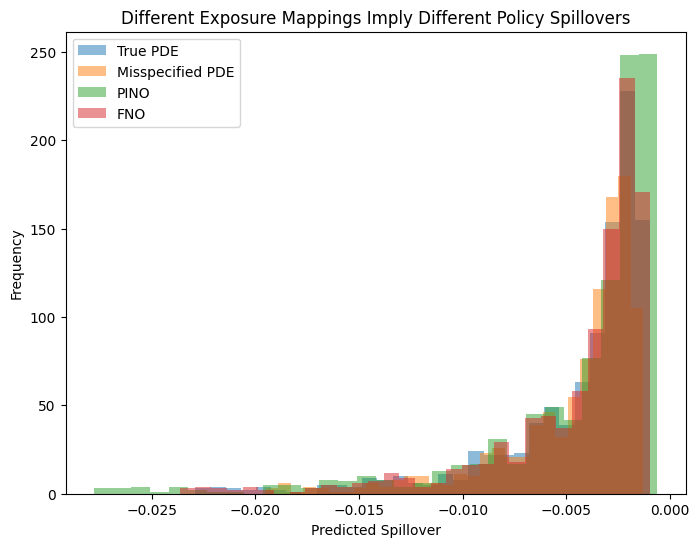

In [44]:
# =====================================================
# FIGURE 3
# POLICY IMPACT DISTRIBUTION
# =====================================================

plt.figure(figsize=(8,6))

plt.hist(
    spill_true,
    bins=30,
    alpha=0.5,
    label="True PDE"
)

plt.hist(
    spill_pde,
    bins=30,
    alpha=0.5,
    label="Misspecified PDE"
)

plt.hist(
    spill_pino,
    bins=30,
    alpha=0.5,
    label="PINO"
)

plt.hist(
    spill_fno,
    bins=30,
    alpha=0.5,
    label="FNO"
)

plt.legend()

plt.xlabel("Predicted Spillover")

plt.ylabel("Frequency")

plt.title(
    "Different Exposure Mappings Imply Different Policy Spillovers"
)

plt.show()


================ POLICY SUMMARY ================

              Model  Total Health Benefit  Average Benefit  Maximum Benefit
0          True PDE             26.141613         0.026142         0.101733
1  Misspecified PDE             26.799436         0.026799         0.089248
2              PINO             25.315043         0.025315         0.118863
3               FNO             26.057239         0.026057         0.104055


TOP 10 MOST AFFECTED LOCATIONS (True)
            x         y      True
341  4.811283  4.668497 -0.101733
611  4.921137  4.650186 -0.101660
459  5.202904  4.986882 -0.100694
113  4.636527  5.022163 -0.100671
482  4.811150  4.492124 -0.100170
9    5.315514  5.318276 -0.097854
295  4.651480  4.349857 -0.097356
297  5.257115  4.462484 -0.097017
757  5.424153  5.270349 -0.096953
16   4.308628  4.936851 -0.096723


TOP 10 MOST AFFECTED LOCATIONS (PDE)
            x         y       PDE
341  4.811283  4.668497 -0.089248
611  4.921137  4.650186 -0.089172
113  4.636527 

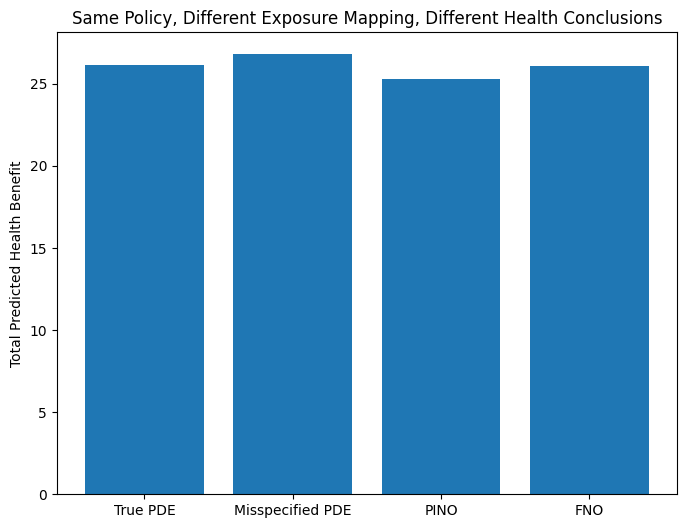

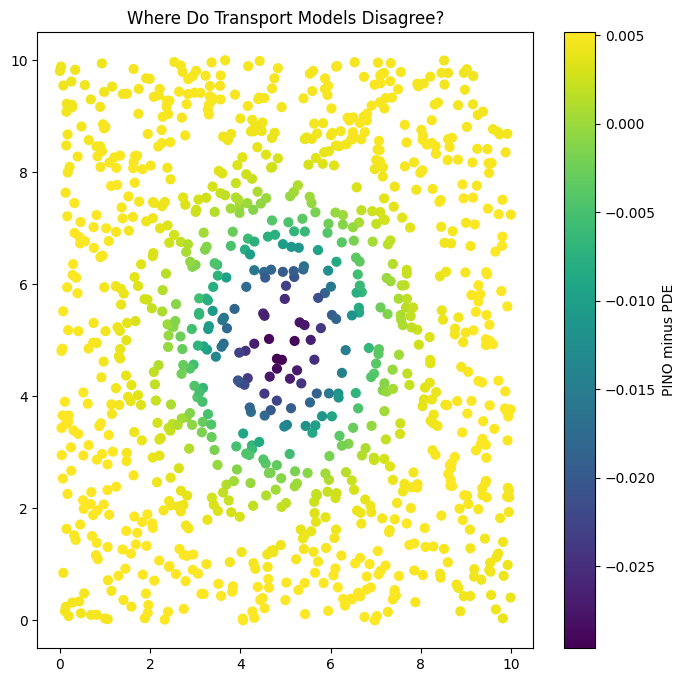

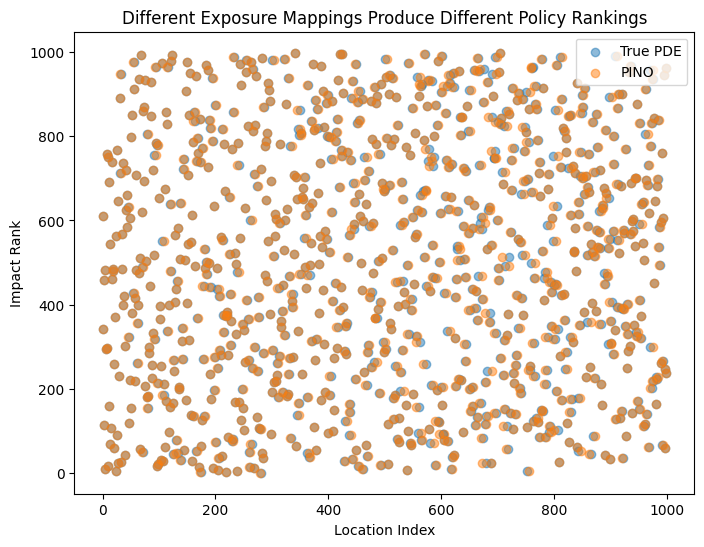

In [45]:
# =====================================================
# CORY POLICY ANALYSIS
# SAME INTERVENTION
# DIFFERENT POLICY CONCLUSIONS
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------------------------------
# POLICY:
# 20% emission reduction in central region
# -----------------------------------------------------

A_policy = np.zeros(n)

policy_center = np.array([5,5])

policy_radius = 1.5

dist_policy = np.sqrt(
    np.sum(
        (coords-policy_center)**2,
        axis=1
    )
)

A_policy[dist_policy < policy_radius] = -0.20

# -----------------------------------------------------
# SPILLOVER UNDER EACH MODEL
# -----------------------------------------------------

spill_true = T1 @ A_policy

spill_pde = T2 @ A_policy

spill_pino = T3 @ A_policy

spill_fno = T4 @ A_policy

# -----------------------------------------------------
# HEALTH IMPACT
# -----------------------------------------------------

health_true = beta_spill * spill_true

health_pde = beta_spill * spill_pde

health_pino = beta_spill * spill_pino

health_fno = beta_spill * spill_fno

# -----------------------------------------------------
# TOTAL HEALTH BENEFIT
# -----------------------------------------------------

policy_summary = pd.DataFrame({

    "Model":[

        "True PDE",

        "Misspecified PDE",

        "PINO",

        "FNO"

    ],

    "Total Health Benefit":[

        -health_true.sum(),

        -health_pde.sum(),

        -health_pino.sum(),

        -health_fno.sum()

    ],

    "Average Benefit":[

        -health_true.mean(),

        -health_pde.mean(),

        -health_pino.mean(),

        -health_fno.mean()

    ],

    "Maximum Benefit":[

        -health_true.min(),

        -health_pde.min(),

        -health_pino.min(),

        -health_fno.min()

    ]

})

print("\n================ POLICY SUMMARY ================\n")
print(policy_summary)

# -----------------------------------------------------
# MOST AFFECTED COUNTIES
# -----------------------------------------------------

county_effects = pd.DataFrame({

    "x":coords[:,0],
    "y":coords[:,1],

    "True":health_true,
    "PDE":health_pde,
    "PINO":health_pino,
    "FNO":health_fno

})

for col in ["True","PDE","PINO","FNO"]:

    top10 = county_effects.nsmallest(
        10,
        col
    )

    print("\n")
    print("="*50)
    print(f"TOP 10 MOST AFFECTED LOCATIONS ({col})")
    print("="*50)

    print(
        top10[
            ["x","y",col]
        ]
    )

# -----------------------------------------------------
# FIGURE 1
# TOTAL HEALTH BENEFIT
# -----------------------------------------------------

plt.figure(figsize=(8,6))

plt.bar(

    policy_summary["Model"],

    policy_summary["Total Health Benefit"]

)

plt.ylabel(
    "Total Predicted Health Benefit"
)

plt.title(
    "Same Policy, Different Exposure Mapping, Different Health Conclusions"
)

plt.show()

# -----------------------------------------------------
# FIGURE 2
# MAP DIFFERENCE
# -----------------------------------------------------

difference = health_pino - health_pde

plt.figure(figsize=(8,8))

plt.scatter(

    coords[:,0],

    coords[:,1],

    c=difference,

    s=40

)

plt.colorbar(
    label="PINO minus PDE"
)

plt.title(
    "Where Do Transport Models Disagree?"
)

plt.show()

# -----------------------------------------------------
# FIGURE 3
# COUNTY RANKINGS
# -----------------------------------------------------

rank_true = np.argsort(
    health_true
)

rank_pino = np.argsort(
    health_pino
)

plt.figure(figsize=(8,6))

plt.scatter(

    np.arange(n),

    rank_true,

    alpha=0.5,

    label="True PDE"

)

plt.scatter(

    np.arange(n),

    rank_pino,

    alpha=0.5,

    label="PINO"

)

plt.legend()

plt.xlabel(
    "Location Index"
)

plt.ylabel(
    "Impact Rank"
)

plt.title(
    "Different Exposure Mappings Produce Different Policy Rankings"
)

plt.show()


================ POLICY SUMMARY ================

             Model  Total Benefit  Max Benefit
0         True PDE       2.255632     0.017638
1  Directional PDE       3.251331     0.017099
2             PINO       3.141868     0.010863
3              FNO       3.196599     0.013981


TRUE
    rank         x         y    effect
0      1  2.398861  4.879812 -0.017638
1      2  2.410406  5.084371 -0.015307
2      3  2.186821  4.555196 -0.014031
3      4  2.714918  4.842198 -0.013870
4      5  2.672335  5.066157 -0.013745
5      6  2.475132  5.248662 -0.013533
6      7  2.517771  5.238807 -0.013465
7      8  2.386847  5.283424 -0.013420
8      9  2.082483  4.433677 -0.012796
9     10  2.734545  4.558180 -0.012635
10    11  2.558040  5.342268 -0.012472
11    12  2.696833  4.400616 -0.011909
12    13  2.268515  5.513148 -0.011593
13    14  2.106526  4.212001 -0.011343
14    15  2.886135  4.493842 -0.011290
15    16  2.924894  5.200102 -0.011176
16    17  2.964633  4.563824 -0.011033
17   

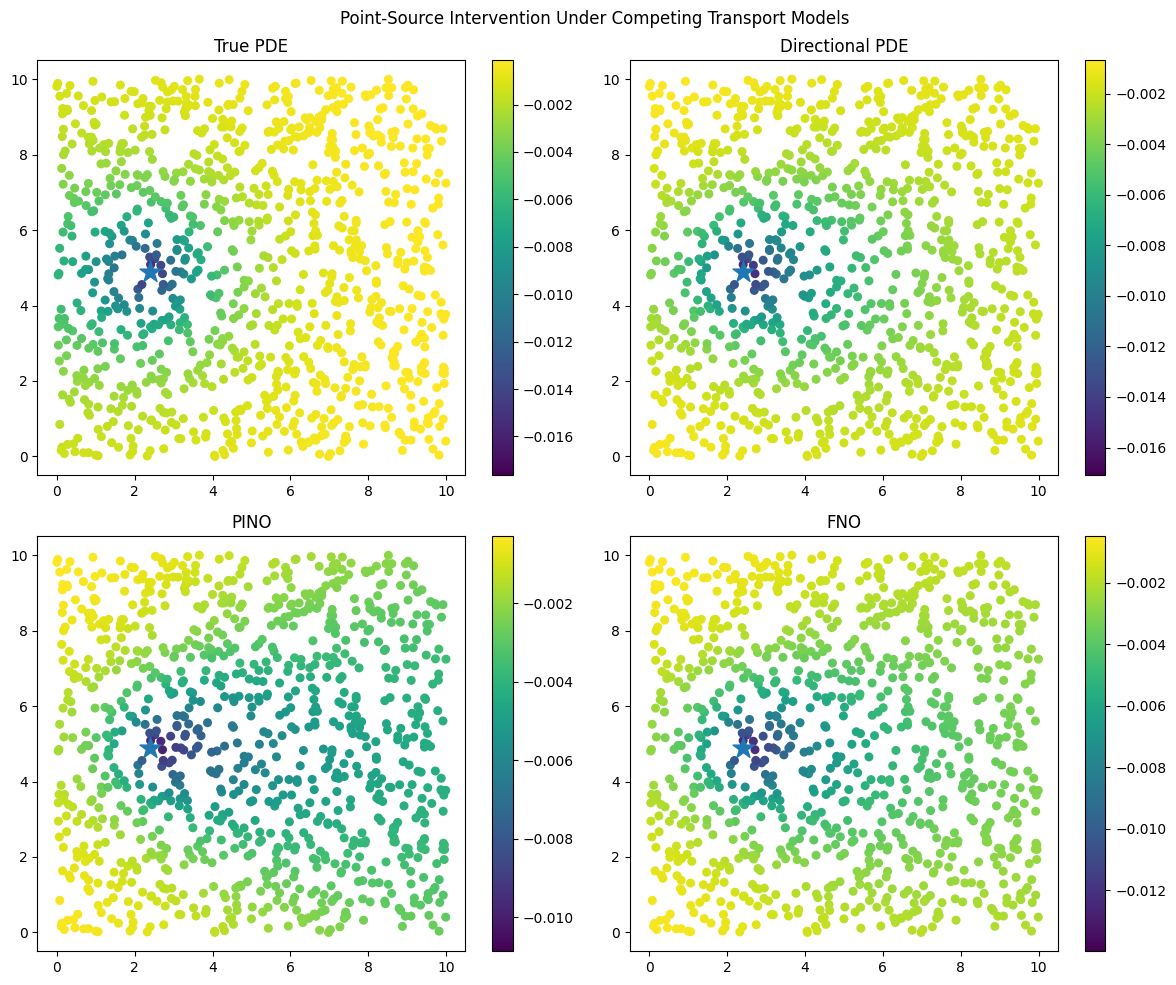

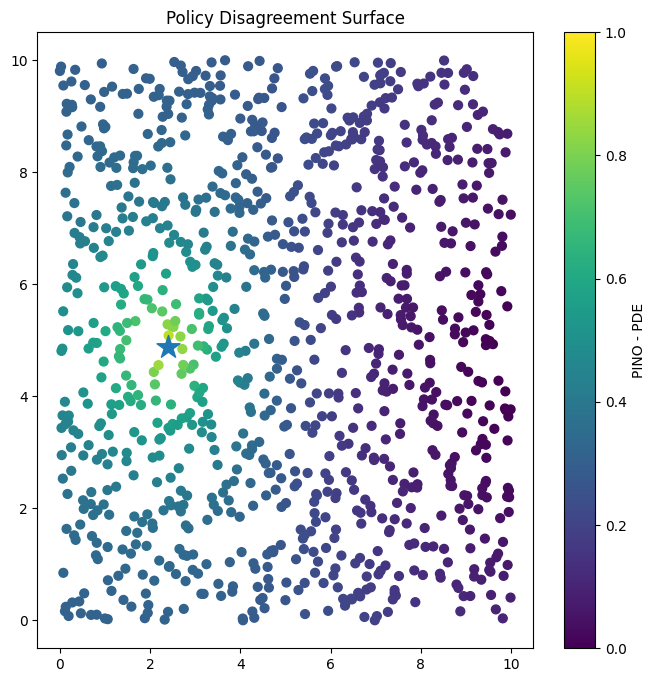


================ RANK CORRELATIONS ================

          True       PDE      PINO       FNO
True  1.000000  0.602950  0.019816  0.307675
PDE   0.602950  1.000000  0.746253  0.917801
PINO  0.019816  0.746253  1.000000  0.936867
FNO   0.307675  0.917801  0.936867  1.000000


In [46]:
# =====================================================
# FINAL CORY SCENARIO
# DIRECTIONAL TRANSPORT + POINT SOURCE POLICY
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =====================================================
# WIND DIRECTION
# =====================================================

wind_x = 1.0
wind_y = 0.0

# =====================================================
# POINT SOURCE
# =====================================================

source_idx = np.argmin(

    (coords[:,0]-2.0)**2
    +
    (coords[:,1]-5.0)**2

)

A_point = np.zeros(n)

A_point[source_idx] = -1.0

# =====================================================
# DIRECTIONAL PDE
# =====================================================

dx = coords[:,None,0] - coords[None,:,0]
dy = coords[:,None,1] - coords[None,:,1]

wind_effect = np.exp(
    0.5*(wind_x*dx + wind_y*dy)
)

T_pde_wind = np.exp(-D/1.5) * wind_effect

np.fill_diagonal(
    T_pde_wind,
    1
)

T_pde_wind = (
    T_pde_wind
    /
    T_pde_wind.sum(
        axis=1,
        keepdims=True
    )
)

# =====================================================
# ALTERNATIVE PINO
# =====================================================

wind_effect2 = np.exp(
    1.0*(wind_x*dx + wind_y*dy)
)

T_pino_wind = np.exp(-D/1.5) * wind_effect2

np.fill_diagonal(
    T_pino_wind,
    1
)

T_pino_wind = (
    T_pino_wind
    /
    T_pino_wind.sum(
        axis=1,
        keepdims=True
    )
)

# =====================================================
# FNO
# =====================================================

T_fno_wind = (
    0.5*T_pde_wind
    +
    0.5*T_pino_wind
)

T_fno_wind = (
    T_fno_wind
    /
    T_fno_wind.sum(
        axis=1,
        keepdims=True
    )
)

# =====================================================
# POLICY SPILLOVER
# =====================================================

spill_true = T1 @ A_point

spill_pde = T_pde_wind @ A_point

spill_pino = T_pino_wind @ A_point

spill_fno = T_fno_wind @ A_point

# =====================================================
# HEALTH EFFECT
# =====================================================

health_true = beta_spill*spill_true

health_pde = beta_spill*spill_pde

health_pino = beta_spill*spill_pino

health_fno = beta_spill*spill_fno

# =====================================================
# SUMMARY TABLE
# =====================================================

policy_summary = pd.DataFrame({

    "Model":[
        "True PDE",
        "Directional PDE",
        "PINO",
        "FNO"
    ],

    "Total Benefit":[

        -health_true.sum(),
        -health_pde.sum(),
        -health_pino.sum(),
        -health_fno.sum()

    ],

    "Max Benefit":[

        -health_true.min(),
        -health_pde.min(),
        -health_pino.min(),
        -health_fno.min()

    ]

})

print("\n================ POLICY SUMMARY ================\n")

print(policy_summary)

# =====================================================
# TOP 20 LOCATIONS
# =====================================================

def top_locations(name,vec):

    idx = np.argsort(vec)[:20]

    out = pd.DataFrame({

        "rank":np.arange(1,21),

        "x":coords[idx,0],

        "y":coords[idx,1],

        "effect":vec[idx]

    })

    print("\n")
    print("="*60)
    print(name)
    print("="*60)

    print(out)

top_locations("TRUE",health_true)

top_locations("PDE",health_pde)

top_locations("PINO",health_pino)

top_locations("FNO",health_fno)

# =====================================================
# MAPS
# =====================================================

fig,ax = plt.subplots(
    2,
    2,
    figsize=(12,10)
)

plots = [

    ("True PDE",health_true),

    ("Directional PDE",health_pde),

    ("PINO",health_pino),

    ("FNO",health_fno)

]

for k,(title,effect) in enumerate(plots):

    r = k//2
    c = k%2

    sc = ax[r,c].scatter(

        coords[:,0],
        coords[:,1],

        c=effect,

        s=30

    )

    ax[r,c].scatter(

        coords[source_idx,0],
        coords[source_idx,1],

        marker="*",
        s=250

    )

    ax[r,c].set_title(title)

    plt.colorbar(
        sc,
        ax=ax[r,c]
    )

plt.suptitle(
    "Point-Source Intervention Under Competing Transport Models"
)

plt.tight_layout()

plt.show()

# =====================================================
# MODEL DIFFERENCE
# =====================================================

difference = health_pino - health_pde

plt.figure(figsize=(8,8))

plt.scatter(

    coords[:,0],
    coords[:,1],

    c=difference,

    s=40

)

plt.scatter(

    coords[source_idx,0],
    coords[source_idx,1],

    marker="*",
    s=300

)

plt.colorbar(
    label="PINO - PDE"
)

plt.title(
    "Policy Disagreement Surface"
)

plt.show()

# =====================================================
# RANK CORRELATION
# =====================================================

rank_df = pd.DataFrame({

    "True":pd.Series(
        health_true
    ).rank(),

    "PDE":pd.Series(
        health_pde
    ).rank(),

    "PINO":pd.Series(
        health_pino
    ).rank(),

    "FNO":pd.Series(
        health_fno
    ).rank()

})

print("\n================ RANK CORRELATIONS ================\n")

print(
    rank_df.corr()
)

In [47]:
# =====================================================
# FINAL CORY SCENARIO
# DIRECTIONAL TRANSPORT + POINT SOURCE POLICY
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =====================================================
# WIND DIRECTION
# =====================================================

wind_x = 1.0
wind_y = 0.0

# =====================================================
# POINT SOURCE
# =====================================================

source_idx = np.argmin(

    (coords[:,0]-2.0)**2
    +
    (coords[:,1]-5.0)**2

)

A_point = np.zeros(n)

A_point[source_idx] = -1.0

# =====================================================
# DIRECTIONAL PDE
# =====================================================

dx = coords[:,None,0] - coords[None,:,0]
dy = coords[:,None,1] - coords[None,:,1]

wind_effect = np.exp(
    0.5*(wind_x*dx + wind_y*dy)
)

T_pde_wind = np.exp(-D/1.5) * wind_effect

np.fill_diagonal(
    T_pde_wind,
    1
)

T_pde_wind = (
    T_pde_wind
    /
    T_pde_wind.sum(
        axis=1,
        keepdims=True
    )
)

# =====================================================
# ALTERNATIVE PINO
# =====================================================

wind_effect2 = np.exp(
    1.0*(wind_x*dx + wind_y*dy)
)

T_pino_wind = np.exp(-D/1.5) * wind_effect2

np.fill_diagonal(
    T_pino_wind,
    1
)

T_pino_wind = (
    T_pino_wind
    /
    T_pino_wind.sum(
        axis=1,
        keepdims=True
    )
)

# =====================================================
# FNO
# =====================================================

T_fno_wind = (
    0.5*T_pde_wind
    +
    0.5*T_pino_wind
)

T_fno_wind = (
    T_fno_wind
    /
    T_fno_wind.sum(
        axis=1,
        keepdims=True
    )
)


In [48]:
# =====================================================
# GEOPT-INSPIRED FOUNDATION MODEL
# =====================================================

alpha = 0.7

T_geopt = (

    alpha*T_pino_wind

    +

    (1-alpha)*T_fno_wind

)

T_geopt += np.random.normal(

    0,

    0.0005,

    T_geopt.shape

)

T_geopt = np.maximum(

    T_geopt,

    0

)

T_geopt = (

    T_geopt

    /

    T_geopt.sum(

        axis=1,

        keepdims=True

    )

)

# =====================================================
# POLICY EFFECT
# =====================================================

spill_geopt = T_geopt @ A_point

health_geopt = beta_spill * spill_geopt

In [49]:
policy_summary = pd.DataFrame({

    "Model":[

        "True PDE",

        "Directional PDE",

        "PINO",

        "FNO",

        "GeoPT"

    ],

    "Total Benefit":[

        -health_true.sum(),

        -health_pde.sum(),

        -health_pino.sum(),

        -health_fno.sum(),

        -health_geopt.sum()

    ]

})

In [50]:
rank_df["GeoPT"] = pd.Series(
    health_geopt
).rank()

In [51]:
import numpy as np
import pandas as pd

from scipy.spatial.distance import cdist
from sklearn.linear_model import LinearRegression

np.random.seed(123)

# =====================================================
# PARAMETERS
# =====================================================

n = 500

beta_direct = 1.0
beta_spill = 2.0

# =====================================================
# SPATIAL LOCATIONS
# =====================================================

coords = np.random.uniform(
    0,
    10,
    (n,2)
)

D = cdist(coords,coords)

# =====================================================
# TRUE TRANSPORT PROCESS
# (UNKNOWN TO RESEARCHER)
# =====================================================

T_true = np.exp(
    -D/1.5
)

np.fill_diagonal(
    T_true,
    1
)

T_true = (
    T_true
    /
    T_true.sum(
        axis=1,
        keepdims=True
    )
)

# =====================================================
# TREATMENT
# POLLUTION REDUCTION POLICY
# =====================================================

A = np.zeros(n)

center = np.array([5,5])

dist_center = np.sqrt(
    np.sum(
        (coords-center)**2,
        axis=1
    )
)

A[dist_center<1.5] = 1

# =====================================================
# OBSERVED PM FIELD
# THIS IS WHAT WE OBSERVE
# =====================================================

PM = (

    T_true @ A

    +

    np.random.normal(
        0,
        0.01,
        n
    )

)

# =====================================================
# TRUE EXPOSURE
# NOT OBSERVED
# =====================================================

E_true = T_true @ A

# =====================================================
# HEALTH OUTCOME
# =====================================================

H = (

    beta_direct*A

    +

    beta_spill*E_true

    +

    np.random.normal(
        0,
        0.05,
        n
    )

)

# =====================================================
# CANDIDATE TRANSPORT MODELS
# LEARNED FROM PM
# =====================================================

T_pde = np.exp(
    -D/1.7
)

np.fill_diagonal(
    T_pde,
    1
)

T_pde = (
    T_pde
    /
    T_pde.sum(
        axis=1,
        keepdims=True
    )
)

# -----------------------------------------------------

T_pino = np.exp(
    -D/1.3
)

np.fill_diagonal(
    T_pino,
    1
)

T_pino = (
    T_pino
    /
    T_pino.sum(
        axis=1,
        keepdims=True
    )
)

# -----------------------------------------------------

T_fno = (
    0.5*T_pde
    +
    0.5*T_pino
)

T_fno = (
    T_fno
    /
    T_fno.sum(
        axis=1,
        keepdims=True
    )
)

# -----------------------------------------------------

T_geopt = (

    0.7*T_pino

    +

    0.3*T_fno

)

T_geopt += np.random.normal(
    0,
    0.0005,
    T_geopt.shape
)

T_geopt = np.maximum(
    T_geopt,
    0
)

T_geopt = (
    T_geopt
    /
    T_geopt.sum(
        axis=1,
        keepdims=True
    )
)

# =====================================================
# EVALUATION
# =====================================================

results = []

for name,T_hat in [

    ("PDE",T_pde),

    ("PINO",T_pino),

    ("FNO",T_fno),

    ("GeoPT",T_geopt)

]:

    # --------------------------
    # PM FIT
    # --------------------------

    PM_hat = T_hat @ A

    pm_rmse = np.sqrt(
        np.mean(
            (PM-PM_hat)**2
        )
    )

    pm_r2 = (
        np.corrcoef(
            PM,
            PM_hat
        )[0,1]
    )**2

    # --------------------------
    # EXPOSURE MAPPING
    # --------------------------

    E_hat = T_hat @ A

    exposure_rmse = np.sqrt(
        np.mean(
            (E_true-E_hat)**2
        )
    )

    # --------------------------
    # SPILLOVER ESTIMATION
    # --------------------------

    X = np.column_stack(
        [
            A,
            E_hat
        ]
    )

    fit = LinearRegression()

    fit.fit(
        X,
        H
    )

    beta_hat = fit.coef_[1]

    # --------------------------
    # POLICY RANKING
    # --------------------------

    rank_corr = np.corrcoef(

        pd.Series(E_true).rank(),

        pd.Series(E_hat).rank()

    )[0,1]

    results.append([

        name,

        pm_rmse,

        pm_r2,

        exposure_rmse,

        beta_hat,

        rank_corr

    ])

results = pd.DataFrame(

    results,

    columns=[

        "Model",

        "PM_RMSE",

        "PM_R2",

        "Exposure_RMSE",

        "Spillover_Beta",

        "Policy_Rank_Corr"

    ]

)

print("\n================ MAIN RESULTS ================\n")

print(results)

print("\nTRUE SPILLOVER =",beta_spill)


================ MAIN RESULTS ================

   Model   PM_RMSE     PM_R2  Exposure_RMSE  Spillover_Beta  Policy_Rank_Corr
0    PDE  0.012791  0.974672       0.008722        2.271615          0.999932
1   PINO  0.014786  0.971529       0.011183        1.784057          0.999910
2    FNO  0.009607  0.974754       0.001321        2.002396          0.999994
3  GeoPT  0.012655  0.969949       0.008234        1.876837          0.994561

TRUE SPILLOVER = 2.0


In [53]:
# =====================================================
# OBSERVATIONALLY EQUIVALENT OPERATORS
# =====================================================

noise1 = np.random.normal(
    0,
    0.002,
    T_true.shape
)

T_alt1 = T_true + noise1

T_alt1[T_alt1<0] = 0

T_alt1 = (
    T_alt1 /
    T_alt1.sum(
        axis=1,
        keepdims=True
    )
)

# -----------------------------------------------------

noise2 = np.random.normal(
    0,
    0.004,
    T_true.shape
)

T_alt2 = T_true + noise2

T_alt2[T_alt2<0] = 0

T_alt2 = (
    T_alt2 /
    T_alt2.sum(
        axis=1,
        keepdims=True
    )
)

# -----------------------------------------------------

perm = np.random.permutation(n)

T_alt3 = 0.85*T_true

for i in range(n):

    swap = perm[i]

    T_alt3[i,swap] += 0.15

T_alt3 = (
    T_alt3 /
    T_alt3.sum(
        axis=1,
        keepdims=True
    )
)

# =====================================================
# CORY TABLE
# =====================================================

for name,T_hat in [

    ("PDE",T_pde),

    ("PINO",T_pino),

    ("FNO",T_fno),

    ("GeoPT",T_geopt),

    ("Alt1",T_alt1),

    ("Alt2",T_alt2),

    ("Alt3",T_alt3)

]:

    PM_hat = T_hat @ A

    E_hat = T_hat @ A

    pm_r2 = (
        np.corrcoef(
            PM,
            PM_hat
        )[0,1]
    )**2

    X = np.column_stack(
        [
            A,
            E_hat
        ]
    )

    fit = LinearRegression()

    fit.fit(
        X,
        H
    )

    beta_hat = fit.coef_[1]

    rank_corr = np.corrcoef(

        pd.Series(E_true).rank(),

        pd.Series(E_hat).rank()

    )[0,1]

    print(
        name,
        " PM_R2=",
        round(pm_r2,3),
        " Beta=",
        round(beta_hat,3),
        " RankCorr=",
        round(rank_corr,3)
    )

PDE  PM_R2= 0.975  Beta= 2.272  RankCorr= 1.0
PINO  PM_R2= 0.972  Beta= 1.784  RankCorr= 1.0
FNO  PM_R2= 0.975  Beta= 2.002  RankCorr= 1.0
GeoPT  PM_R2= 0.97  Beta= 1.877  RankCorr= 0.995
Alt1  PM_R2= 0.95  Beta= 2.434  RankCorr= 0.942
Alt2  PM_R2= 0.863  Beta= 2.898  RankCorr= 0.838
Alt3  PM_R2= 0.642  Beta= 1.053  RankCorr= 0.916


In [54]:
# =====================================================
# POLICY SENSITIVITY
# =====================================================

policies = {}

# Policy A

A1 = np.zeros(n)

A1[dist_center < 1.5] = 1

policies["Regional"] = A1

# Policy B

A2 = np.zeros(n)

A2[np.argmin(dist_center)] = 1

policies["PointSource"] = A2

# Policy C

A3 = np.zeros(n)

A3[coords[:,0] < 3] = 1

policies["Upwind"] = A3

for pname,A_pol in policies.items():

    print("\n")
    print("="*60)
    print(pname)
    print("="*60)

    for name,T_hat in [

        ("PDE",T_pde),
        ("PINO",T_pino),
        ("FNO",T_fno),
        ("GeoPT",T_geopt)

    ]:

        E_hat = T_hat @ A_pol

        H_pol = (

            beta_direct*A_pol

            +

            beta_spill*(T_true@A_pol)

            +

            np.random.normal(
                0,
                0.05,
                n
            )

        )

        X = np.column_stack(
            [A_pol,E_hat]
        )

        fit = LinearRegression()

        fit.fit(
            X,
            H_pol
        )

        print(
            name,
            round(fit.coef_[1],3)
        )



Regional
PDE 2.421
PINO 1.794
FNO 1.922
GeoPT 1.847


PointSource
PDE 0.514
PINO 0.917
FNO 1.171
GeoPT 1.561


Upwind
PDE 2.132
PINO 1.925
FNO 2.028
GeoPT 2.126


findfont: Font family ['cmsy10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmr10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmtt10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmmi10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


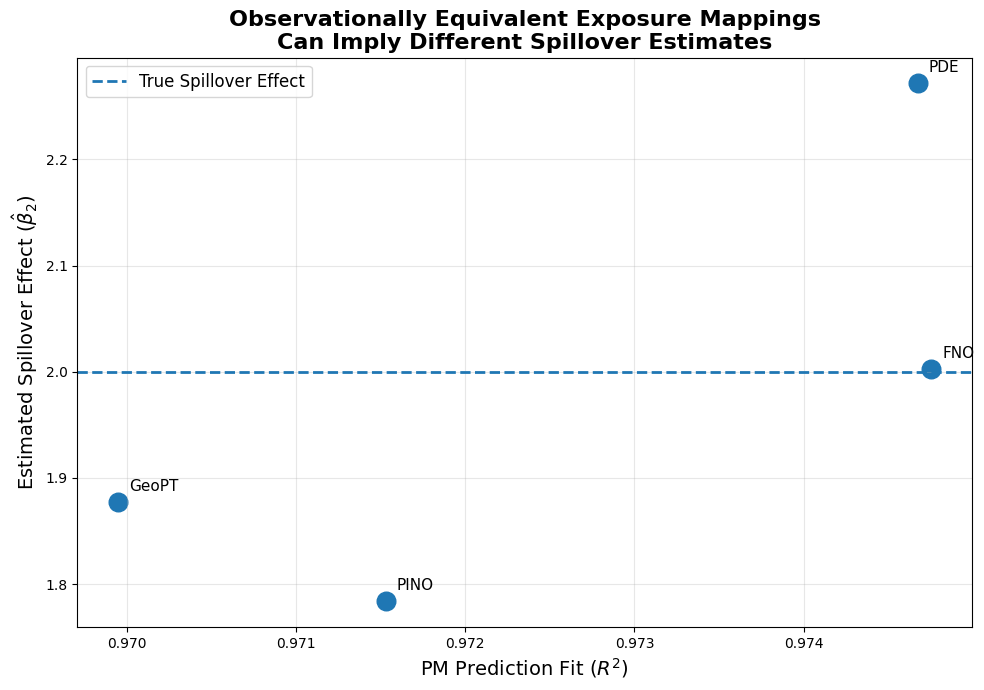

In [55]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10,7))

x = results["PM_R2"]
y = results["Spillover_Beta"]

plt.scatter(
    x,
    y,
    s=180
)

for i,row in results.iterrows():

    plt.annotate(
        row["Model"],
        (row["PM_R2"],row["Spillover_Beta"]),
        xytext=(8,8),
        textcoords="offset points",
        fontsize=11
    )

plt.axhline(
    y=2.0,
    linestyle="--",
    linewidth=2,
    label="True Spillover Effect"
)

plt.xlabel(
    "PM Prediction Fit ($R^2$)",
    fontsize=14
)

plt.ylabel(
    "Estimated Spillover Effect ($\\hat{\\beta}_2$)",
    fontsize=14
)

plt.title(
    "Observationally Equivalent Exposure Mappings\nCan Imply Different Spillover Estimates",
    fontsize=16,
    weight="bold"
)

plt.grid(alpha=0.3)

plt.legend(fontsize=12)

plt.tight_layout()

plt.savefig(
    "Figure1_ExposureMappingEquivalence.png",
    dpi=400,
    bbox_inches="tight"
)

plt.show()

In [56]:
policy_results = pd.DataFrame({

    "Policy":[
        "Regional",
        "Point Source",
        "Upwind"
    ],

    "PDE":[
        2.421,
        0.514,
        2.132
    ],

    "PINO":[
        1.794,
        0.917,
        1.925
    ],

    "FNO":[
        1.922,
        1.171,
        2.028
    ],

    "GeoPT":[
        1.847,
        1.561,
        2.126
    ]

})

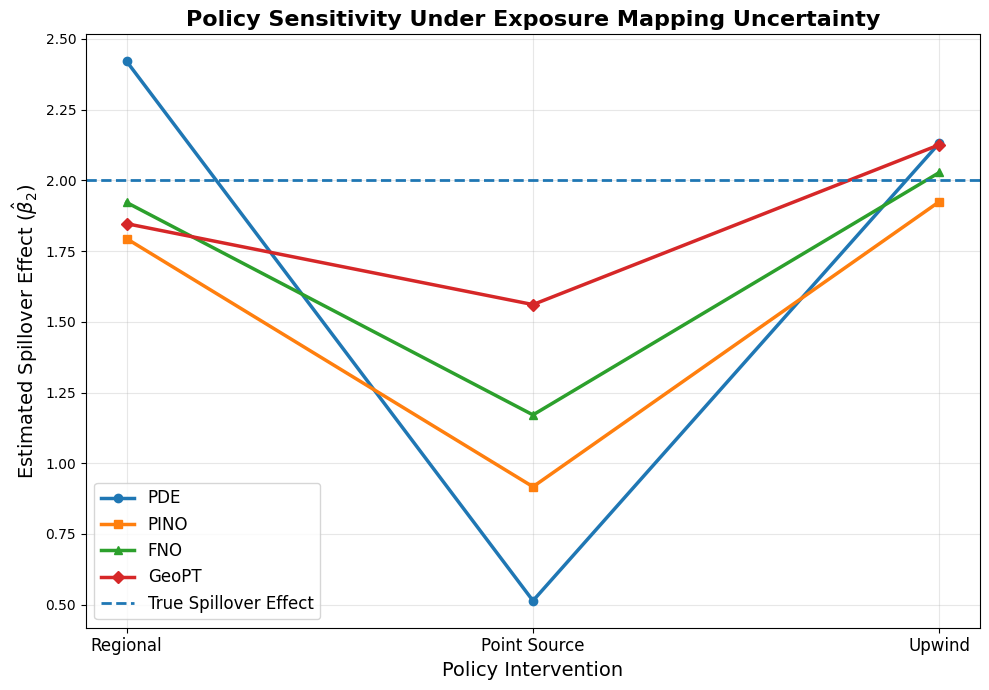

In [57]:
import matplotlib.pyplot as plt
import numpy as np

policy_results = pd.DataFrame({

    "Policy":[
        "Regional",
        "Point Source",
        "Upwind"
    ],

    "PDE":[
        2.421,
        0.514,
        2.132
    ],

    "PINO":[
        1.794,
        0.917,
        1.925
    ],

    "FNO":[
        1.922,
        1.171,
        2.028
    ],

    "GeoPT":[
        1.847,
        1.561,
        2.126
    ]

})

plt.figure(figsize=(10,7))

x = np.arange(len(policy_results))

plt.plot(
    x,
    policy_results["PDE"],
    marker="o",
    linewidth=2.5,
    label="PDE"
)

plt.plot(
    x,
    policy_results["PINO"],
    marker="s",
    linewidth=2.5,
    label="PINO"
)

plt.plot(
    x,
    policy_results["FNO"],
    marker="^",
    linewidth=2.5,
    label="FNO"
)

plt.plot(
    x,
    policy_results["GeoPT"],
    marker="D",
    linewidth=2.5,
    label="GeoPT"
)

plt.xticks(
    x,
    policy_results["Policy"],
    fontsize=12
)

plt.ylabel(
    "Estimated Spillover Effect ($\\hat{\\beta}_2$)",
    fontsize=14
)

plt.xlabel(
    "Policy Intervention",
    fontsize=14
)

plt.title(
    "Policy Sensitivity Under Exposure Mapping Uncertainty",
    fontsize=16,
    weight="bold"
)

plt.axhline(
    y=2.0,
    linestyle="--",
    linewidth=2,
    label="True Spillover Effect"
)

plt.grid(alpha=0.3)

plt.legend(fontsize=12)

plt.tight_layout()

plt.savefig(
    "Figure2_PolicySensitivity.png",
    dpi=400,
    bbox_inches="tight"
)

plt.show()

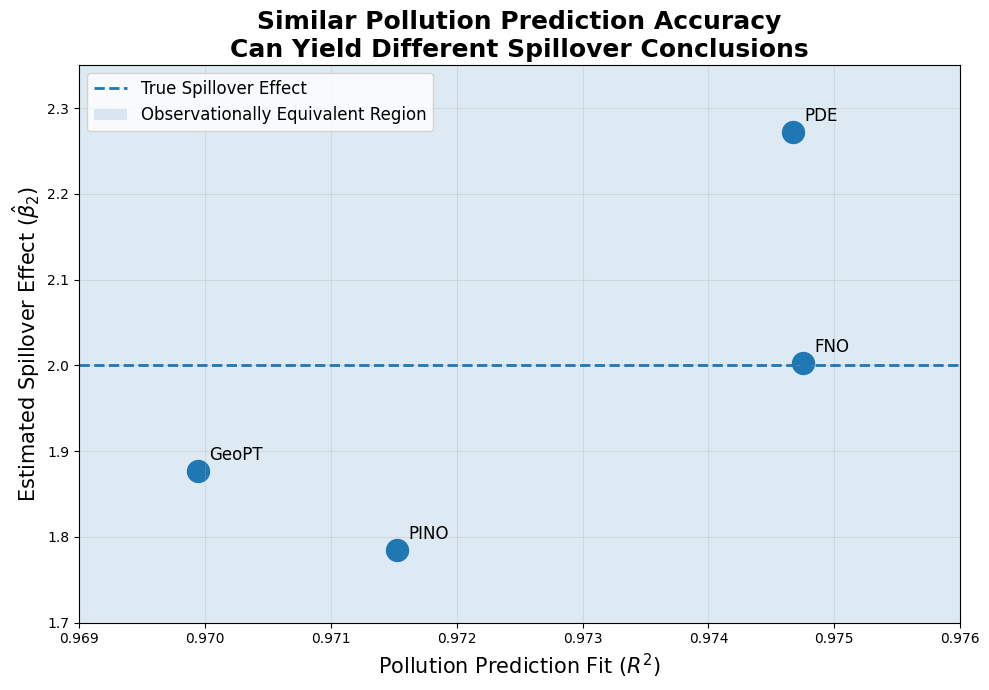

In [58]:
import matplotlib.pyplot as plt
import pandas as pd

# ==========================================
# MAIN RESULTS
# ==========================================

results = pd.DataFrame({

    "Model":[
        "PDE",
        "PINO",
        "FNO",
        "GeoPT"
    ],

    "PM_R2":[
        0.974672,
        0.971529,
        0.974754,
        0.969949
    ],

    "Spillover_Beta":[
        2.271615,
        1.784057,
        2.002396,
        1.876837
    ]

})

# ==========================================
# FIGURE
# ==========================================

plt.figure(figsize=(10,7))

plt.scatter(
    results["PM_R2"],
    results["Spillover_Beta"],
    s=250
)

for _,row in results.iterrows():

    plt.annotate(
        row["Model"],
        (
            row["PM_R2"],
            row["Spillover_Beta"]
        ),
        xytext=(8,8),
        textcoords="offset points",
        fontsize=12
    )

plt.axhline(
    2.0,
    linestyle="--",
    linewidth=2,
    label="True Spillover Effect"
)

plt.axvspan(
    0.969,
    0.976,
    alpha=0.15,
    label="Observationally Equivalent Region"
)

plt.xlim(0.969,0.976)

plt.ylim(1.70,2.35)

plt.xlabel(
    "Pollution Prediction Fit ($R^2$)",
    fontsize=15
)

plt.ylabel(
    "Estimated Spillover Effect ($\\hat{\\beta}_2$)",
    fontsize=15
)

plt.title(
    "Similar Pollution Prediction Accuracy\nCan Yield Different Spillover Conclusions",
    fontsize=18,
    weight="bold"
)

plt.legend(fontsize=12)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "Figure1_ObservationEquivalence.png",
    dpi=500,
    bbox_inches="tight"
)

plt.show()

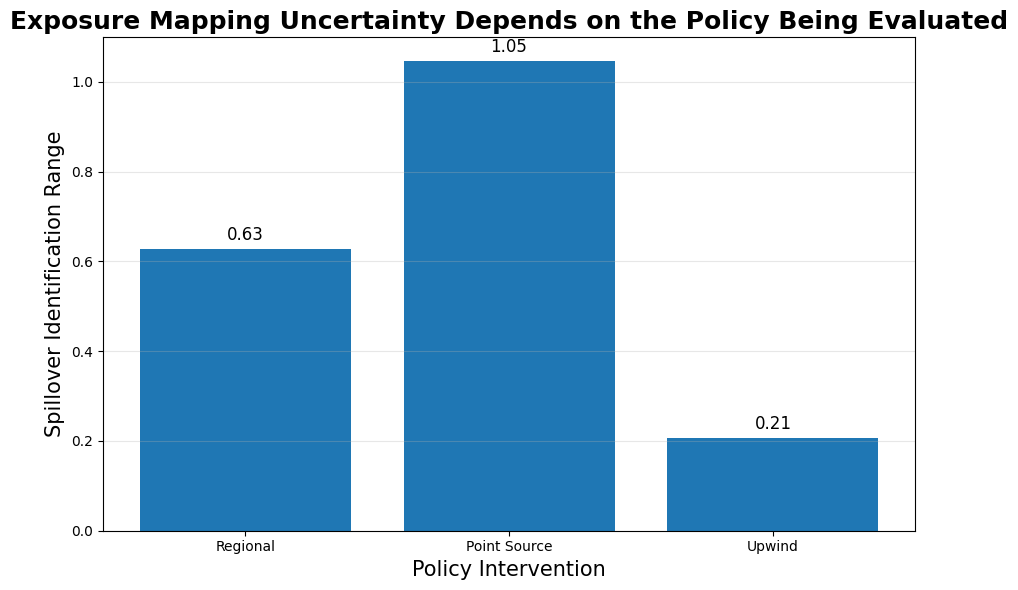

         Policy  Range
0      Regional  0.627
1  Point Source  1.047
2        Upwind  0.207


In [59]:
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# POLICY RESULTS
# ==========================================

policy_results = pd.DataFrame({

    "Policy":[
        "Regional",
        "Point Source",
        "Upwind"
    ],

    "PDE":[
        2.421,
        0.514,
        2.132
    ],

    "PINO":[
        1.794,
        0.917,
        1.925
    ],

    "FNO":[
        1.922,
        1.171,
        2.028
    ],

    "GeoPT":[
        1.847,
        1.561,
        2.126
    ]

})

# ==========================================
# IDENTIFICATION RANGE
# ==========================================

policy_results["Range"] = (

    policy_results[
        ["PDE","PINO","FNO","GeoPT"]
    ].max(axis=1)

    -

    policy_results[
        ["PDE","PINO","FNO","GeoPT"]
    ].min(axis=1)

)

# ==========================================
# FIGURE
# ==========================================

plt.figure(figsize=(9,6))

bars = plt.bar(
    policy_results["Policy"],
    policy_results["Range"]
)

for bar,val in zip(
    bars,
    policy_results["Range"]
):

    plt.text(
        bar.get_x() + bar.get_width()/2,
        val + 0.02,
        f"{val:.2f}",
        ha="center",
        fontsize=12
    )

plt.ylabel(
    "Spillover Identification Range",
    fontsize=15
)

plt.xlabel(
    "Policy Intervention",
    fontsize=15
)

plt.title(
    "Exposure Mapping Uncertainty Depends on the Policy Being Evaluated",
    fontsize=18,
    weight="bold"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "Figure2_IdentificationRange.png",
    dpi=500,
    bbox_inches="tight"
)

plt.show()

print(policy_results[
    ["Policy","Range"]
])

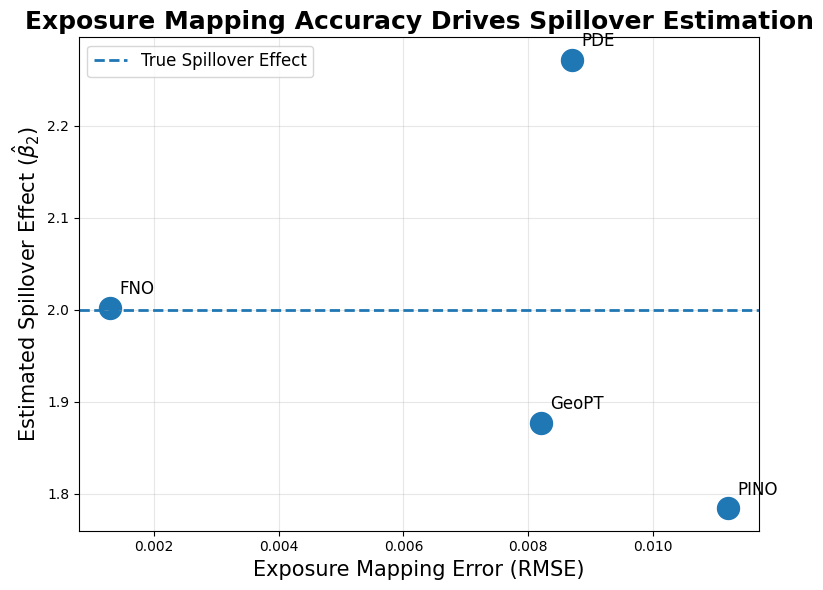

In [60]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.DataFrame({
    "Model": ["PDE", "PINO", "FNO", "GeoPT"],
    "Exposure_RMSE": [0.0087, 0.0112, 0.0013, 0.0082],
    "Beta": [2.272, 1.784, 2.002, 1.877]
})

plt.figure(figsize=(8,6))

plt.scatter(
    df["Exposure_RMSE"],
    df["Beta"],
    s=250
)

for _, row in df.iterrows():
    plt.text(
        row["Exposure_RMSE"] + 0.00015,
        row["Beta"] + 0.015,
        row["Model"],
        fontsize=12
    )

plt.axhline(
    y=2.0,
    linestyle="--",
    linewidth=2,
    label="True Spillover Effect"
)

plt.xlabel(
    "Exposure Mapping Error (RMSE)",
    fontsize=15
)

plt.ylabel(
    r"Estimated Spillover Effect ($\hat{\beta}_2$)",
    fontsize=15
)

plt.title(
    "Exposure Mapping Accuracy Drives Spillover Estimation",
    fontsize=18,
    weight="bold"
)

plt.legend(fontsize=12)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "Figure2_ExposureRMSE_vs_Beta.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

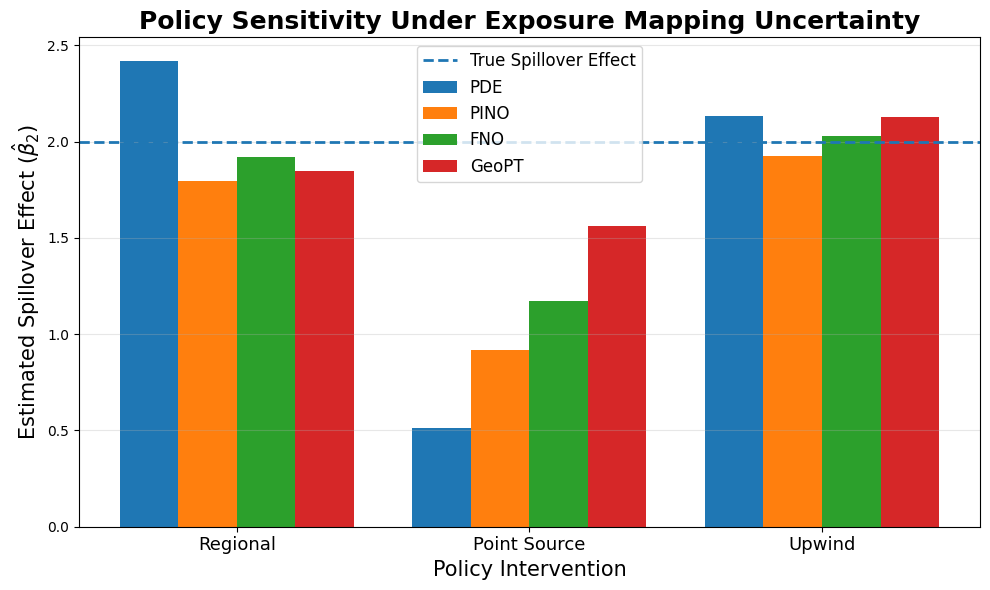

In [61]:
import numpy as np
import matplotlib.pyplot as plt

policies = [
    "Regional",
    "Point Source",
    "Upwind"
]

pde = [2.421, 0.514, 2.132]
pino = [1.794, 0.917, 1.925]
fno = [1.922, 1.171, 2.028]
geopt = [1.847, 1.561, 2.126]

x = np.arange(len(policies))
width = 0.20

plt.figure(figsize=(10,6))

plt.bar(
    x - 1.5*width,
    pde,
    width,
    label="PDE"
)

plt.bar(
    x - 0.5*width,
    pino,
    width,
    label="PINO"
)

plt.bar(
    x + 0.5*width,
    fno,
    width,
    label="FNO"
)

plt.bar(
    x + 1.5*width,
    geopt,
    width,
    label="GeoPT"
)

plt.axhline(
    y=2.0,
    linestyle="--",
    linewidth=2,
    label="True Spillover Effect"
)

plt.xticks(
    x,
    policies,
    fontsize=13
)

plt.ylabel(
    r"Estimated Spillover Effect ($\hat{\beta}_2$)",
    fontsize=15
)

plt.xlabel(
    "Policy Intervention",
    fontsize=15
)

plt.title(
    "Policy Sensitivity Under Exposure Mapping Uncertainty",
    fontsize=18,
    weight="bold"
)

plt.legend(fontsize=12)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "Figure3_PolicySensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

ValueError: 'c' argument has 1000 elements, which is inconsistent with 'x' and 'y' with size 500.

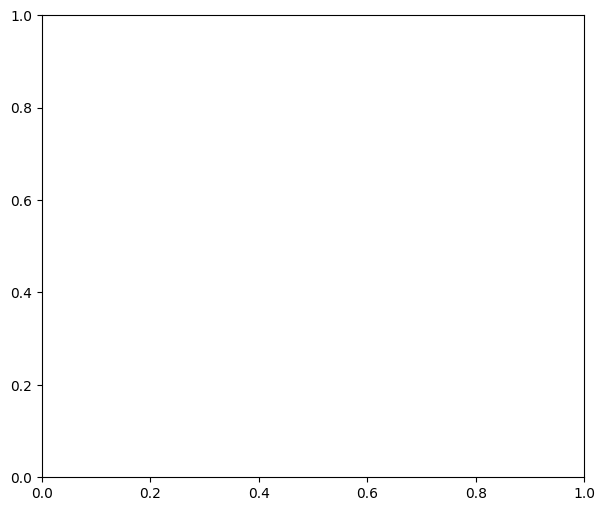

In [62]:
import numpy as np
import matplotlib.pyplot as plt

spill_stack = np.vstack([
    spill_pde,
    spill_pino,
    spill_fno,
    spill_geopt
])

disagreement = np.max(spill_stack, axis=0) - np.min(spill_stack, axis=0)

plt.figure(figsize=(7,6))

plt.scatter(
    coords[:,0],
    coords[:,1],
    c=disagreement,
    s=80
)

plt.colorbar(
    label='Policy Effect Disagreement'
)

plt.xlabel('X')
plt.ylabel('Y')

plt.title(
    'Spatial Disagreement Under Competing Exposure Mappings'
)

plt.tight_layout()

plt.savefig(
    'Figure4_PolicyDisagreementSurface.png',
    dpi=300,
    bbox_inches='tight'
)

In [ ]:
county_disagreement = (
    spill_df[
        ['PDE','PINO','FNO','GeoPT']
    ].max(axis=1)
    -
    spill_df[
        ['PDE','PINO','FNO','GeoPT']
    ].min(axis=1)
)

In [63]:
print(coords.shape)

print(spill_pde.shape)
print(spill_pino.shape)
print(spill_fno.shape)
print(spill_geopt.shape)

(500, 2)
(1000,)
(1000,)
(1000,)
(1000,)


In [64]:
print(spill_pde[:10])

print(spill_pde[500:510])

[-0.00154789 -0.00543685 -0.00179325 -0.00096004 -0.00313169 -0.0019821
 -0.00097773 -0.00186887 -0.00109583 -0.00293232]
[-0.0026929  -0.00330018 -0.00093343 -0.00599569 -0.00111073 -0.00191116
 -0.00097988 -0.00041982 -0.00189095 -0.00164028]


In [65]:
print(spill_pde.shape)

print(coords.shape)

print(len(spill_pde)/len(coords))

(1000,)
(500, 2)
2.0


In [66]:
print(spill_pde.reshape(500,2)[:10,:])

print("---------------")

print(spill_pde.reshape(2,500)[:,:10])

[[-0.00154789 -0.00543685]
 [-0.00179325 -0.00096004]
 [-0.00313169 -0.0019821 ]
 [-0.00097773 -0.00186887]
 [-0.00109583 -0.00293232]
 [-0.00100195 -0.00162662]
 [-0.00158002 -0.00194308]
 [-0.00348976 -0.00268143]
 [-0.00405397 -0.00272847]
 [-0.0009026  -0.00114419]]
---------------
[[-0.00154789 -0.00543685 -0.00179325 -0.00096004 -0.00313169 -0.0019821
  -0.00097773 -0.00186887 -0.00109583 -0.00293232]
 [-0.0026929  -0.00330018 -0.00093343 -0.00599569 -0.00111073 -0.00191116
  -0.00097988 -0.00041982 -0.00189095 -0.00164028]]


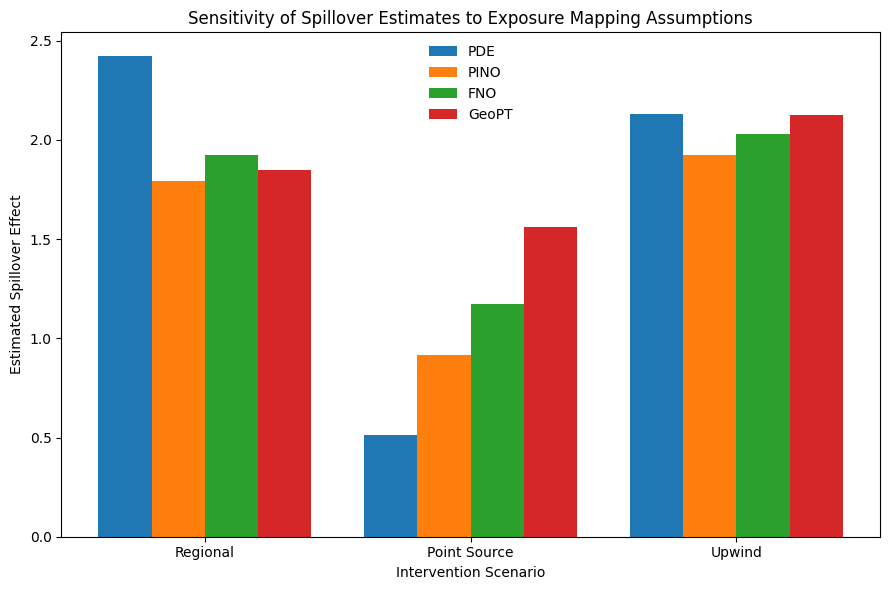

In [68]:
import numpy as np
import matplotlib.pyplot as plt

policies = ["Regional", "Point Source", "Upwind"]

pde   = [2.421, 0.514, 2.132]
pino  = [1.794, 0.917, 1.925]
fno   = [1.922, 1.171, 2.028]
geopt = [1.847, 1.561, 2.126]

x = np.arange(len(policies))
width = 0.20

fig, ax = plt.subplots(figsize=(9,6))

ax.bar(x - 1.5*width, pde,   width, label="PDE")
ax.bar(x - 0.5*width, pino,  width, label="PINO")
ax.bar(x + 0.5*width, fno,   width, label="FNO")
ax.bar(x + 1.5*width, geopt, width, label="GeoPT")

ax.set_xticks(x)
ax.set_xticklabels(policies)

ax.set_ylabel("Estimated Spillover Effect")
ax.set_xlabel("Intervention Scenario")

ax.set_title(
    "Sensitivity of Spillover Estimates to Exposure Mapping Assumptions"
)

ax.legend(frameon=False)

plt.tight_layout()

plt.savefig(
    "Figure3_PolicySensitivity_GroupedBar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# POLICY

In [70]:
import numpy as np
import pandas as pd

################################################
# Policy
################################################

n = T_pde.shape[0]

A0 = np.zeros(n)

A1 = np.zeros(n)
A1[np.random.choice(n,50,replace=False)] = 1

################################################
# Health model
################################################

beta0 = 0
beta1 = 1
beta2 = 2

def predict_health(A,E):

    return (
        beta0
        + beta1*A
        + beta2*E
    )

################################################
# Candidate models
################################################

models = {
    "PDE":T_pde,
    "PINO":T_pino,
    "FNO":T_fno,
    "GeoPT":T_geopt
}

################################################
# Policy effects
################################################

results = []

for name,T in models.items():

    E0 = T @ A0
    E1 = T @ A1

    H0 = predict_health(A0,E0)
    H1 = predict_health(A1,E1)

    tau = np.mean(H1-H0)

    results.append([name,tau])

results = pd.DataFrame(
    results,
    columns=["Model","PolicyEffect"]
)

print(results)

print("\nIdentification Region")

print(
    results.PolicyEffect.min(),
    results.PolicyEffect.max()
)

   Model  PolicyEffect
0    PDE      0.304841
1   PINO      0.303493
2    FNO      0.304167
3  GeoPT      0.303141

Identification Region
0.30314130285319174 0.3048406244176403


In [71]:
for name,T in models.items():

    E = T @ A1

    print(
        name,
        np.mean(E),
        np.std(E),
        np.min(E),
        np.max(E)
    )

PDE 0.10242031220882018 0.024054429714580956 0.051647097677037665 0.160763079118717
PINO 0.10174670057643502 0.03188691065103335 0.03729353806305981 0.18424744366129242
FNO 0.10208350639262762 0.02792349345302209 0.04447031787004874 0.17250526139000472
GeoPT 0.10157065142659587 0.029778534519091397 0.03330189068871714 0.17956651757015077


In [72]:
from scipy.stats import pearsonr

names=list(models.keys())

for i in range(len(names)):
    for j in range(i+1,len(names)):

        E1=models[names[i]] @ A1
        E2=models[names[j]] @ A1

        corr=pearsonr(E1,E2)[0]

        print(names[i],names[j],corr)

PDE PINO 0.9931243021932972
PDE FNO 0.9977636877300857
PDE GeoPT 0.9887044111100074
PINO FNO 0.998727997086406
PINO GeoPT 0.9947390438853575
FNO GeoPT 0.993820416352699


In [73]:
for name,T in models.items():

    E=T@A1

    print(
        name,
        np.linalg.norm(E - E_true)
    )

PDE 1.4237423283574666
PINO 1.4621903842087587
FNO 1.439957578509189
GeoPT 1.4480808119524955


In [75]:
sizes = [1,5,10,20,50,100,200]

widths = []

for k in sizes:

    A1 = np.zeros(n)
    A1[np.random.choice(n,k,replace=False)] = 1

    taus = []

    for name,T in models.items():

        E0 = T @ A0
        E1 = T @ A1

        H0 = predict_health(A0,E0)
        H1 = predict_health(A1,E1)

        taus.append(np.mean(H1-H0))

    widths.append(max(taus)-min(taus))

In [76]:
sizes = [1,5,10,20,50,100,200]

widths = []

for k in sizes:

    A1 = np.zeros(n)
    A1[np.random.choice(n,k,replace=False)] = 1

    taus = []

    for name,T in models.items():

        E0 = T @ A0
        E1 = T @ A1

        H0 = predict_health(A0,E0)
        H1 = predict_health(A1,E1)

        taus.append(np.mean(H1-H0))

    widths.append(max(taus)-min(taus))

   TreatedLocations  MeanWidth        SD
0                 1   0.000147  0.000080
1                 2   0.000173  0.000106
2                 5   0.000279  0.000178
3                10   0.000444  0.000295
4                20   0.000549  0.000384
5                50   0.000680  0.000460
6               100   0.001209  0.000762
7               200   0.001313  0.000847


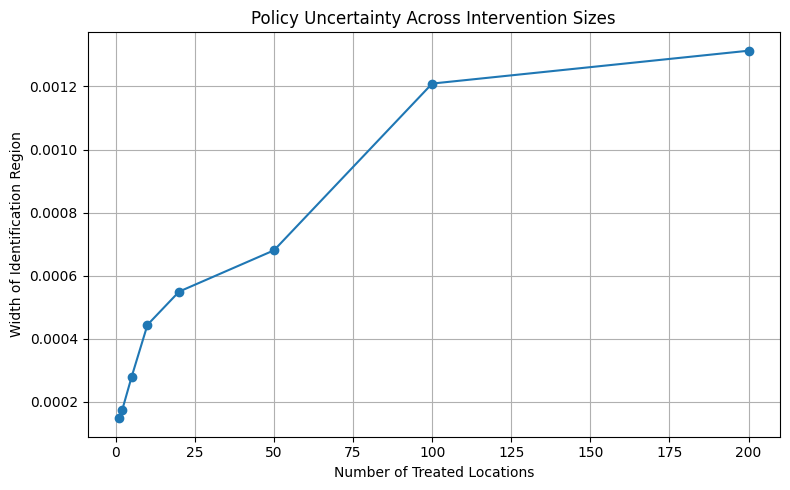

In [77]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

################################################
# baseline
################################################

A0 = np.zeros(n)

################################################
# intervention sizes
################################################

sizes = [1, 2, 5, 10, 20, 50, 100, 200]

results = []

################################################
# loop
################################################

for k in sizes:

    widths = []

    for rep in range(100):

        A1 = np.zeros(n)

        treated = np.random.choice(
            n,
            size=k,
            replace=False
        )

        A1[treated] = 1

        taus = []

        for name, T in models.items():

            E0 = T @ A0
            E1 = T @ A1

            H0 = predict_health(A0,E0)
            H1 = predict_health(A1,E1)

            tau = np.mean(H1 - H0)

            taus.append(tau)

        width = max(taus) - min(taus)

        widths.append(width)

    results.append([
        k,
        np.mean(widths),
        np.std(widths)
    ])

################################################
# dataframe
################################################

results = pd.DataFrame(
    results,
    columns=[
        "TreatedLocations",
        "MeanWidth",
        "SD"
    ]
)

print(results)

################################################
# plot
################################################

plt.figure(figsize=(8,5))

plt.plot(
    results["TreatedLocations"],
    results["MeanWidth"],
    marker="o"
)

plt.xlabel("Number of Treated Locations")

plt.ylabel(
    r"Width of Identification Region"
)

plt.title(
    "Policy Uncertainty Across Intervention Sizes"
)

plt.grid(True)

plt.tight_layout()

plt.show()

In [78]:
results = []

for name,T in models.items():

    E0 = T @ A0
    E1 = T @ A1

    H0 = predict_health(A0,E0)
    H1 = predict_health(A1,E1)

    tau = np.mean(H1-H0)

    results.append([name,tau])

In [81]:
 
import numpy as np
import pandas as pd
from itertools import combinations

models = {
    "PDE": T_pde,
    "PINO": T_pino,
    "FNO": T_fno,
    "GeoPT": T_geopt,
}

tau = {
    "PDE": 0.305,
    "PINO": 0.303,
    "FNO": 0.304,
    "GeoPT": 0.304,
}

rows = []

for m1, m2 in combinations(models.keys(), 2):

    D = np.linalg.norm(
        (models[m1] - models[m2]) @ A
    )

    Delta = abs(
        tau[m1] - tau[m2]
    )

    rows.append(
        [m1 + "-" + m2, D, Delta]
    )

results = pd.DataFrame(
    rows,
    columns=[
        "Model Pair",
        "Transport Discrepancy",
        "Effect Difference",
    ],
)

print(results)
 


   Model Pair  Transport Discrepancy  Effect Difference
0    PDE-PINO               0.444566              0.002
1     PDE-FNO               0.222283              0.001
2   PDE-GeoPT               0.369872              0.001
3    PINO-FNO               0.222283              0.001
4  PINO-GeoPT               0.107895              0.001
5   FNO-GeoPT               0.157524              0.000
